In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_csv("C:\\Users\\TechNest computers\\Desktop\\bussines analaysis\\data\\Telco_Customer_Churn_Dataset  (3).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [4]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [5]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

if total_missing == 0:
    print("There are no missing values!")
else:
    print("Missing values were found!")

Total missing values: 0
There are no missing values!


In [9]:
hidden_missing = df.apply(
    lambda column: column.astype("string").str.strip().eq("").sum()
)

print("Empty or whitespace-only values in each column:")
print(hidden_missing[hidden_missing > 0])

Empty or whitespace-only values in each column:
TotalCharges    11
dtype: int64


In [10]:
print(df["TotalCharges"].value_counts().head())
print("TotalCharges data type:", df["TotalCharges"].dtype)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
Name: count, dtype: int64
TotalCharges data type: str


In [11]:
print(df["TotalCharges"].head(10))

print("\nData type:")
print(df["TotalCharges"].dtype)

print("\nType of the first value:")
print(type(df["TotalCharges"].iloc[0]))

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

Data type:
str

Type of the first value:
<class 'str'>


In [12]:
# Replace blank strings and whitespace with missing values
df["TotalCharges"] = df["TotalCharges"].replace(
    r"^\s*$", np.nan, regex=True
)

# Convert TotalCharges to numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check the results
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

Data type: float64
Missing values: 11


In [15]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [16]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']


In [17]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset shape: (7043, 21)

Missing values:
totalcharges    11
dtype: int64


In [18]:
# Summary statistics for numerical columns

print("MEAN")
print(df.mean(numeric_only=True))

print("\nMEDIAN")
print(df.median(numeric_only=True))

print("\nMODE")
print(df.mode().iloc[0])

MEAN
seniorcitizen        0.162147
tenure              32.371149
monthlycharges      64.761692
totalcharges      2283.300441
dtype: float64

MEDIAN
seniorcitizen        0.000
tenure              29.000
monthlycharges      70.350
totalcharges      1397.475
dtype: float64

MODE
customerid                0002-ORFBO
gender                          Male
seniorcitizen                    0.0
partner                           No
dependents                        No
tenure                           1.0
phoneservice                     Yes
multiplelines                     No
internetservice          Fiber optic
onlinesecurity                    No
onlinebackup                      No
deviceprotection                  No
techsupport                       No
streamingtv                       No
streamingmovies                   No
contract              Month-to-month
paperlessbilling                 Yes
paymentmethod       Electronic check
monthlycharges                 20.05
totalcharges        

In [19]:
df.describe()

,seniorcitizen,tenure,monthlycharges,totalcharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
### Analysis of Monthly Charges

The histogram shows the distribution of monthly charges among customers. It helps identify the ranges where monthly charges 
are concentrated and whether the distribution is spread out or clustered. This information helps the company understand 
its customers' monthly payment patterns.


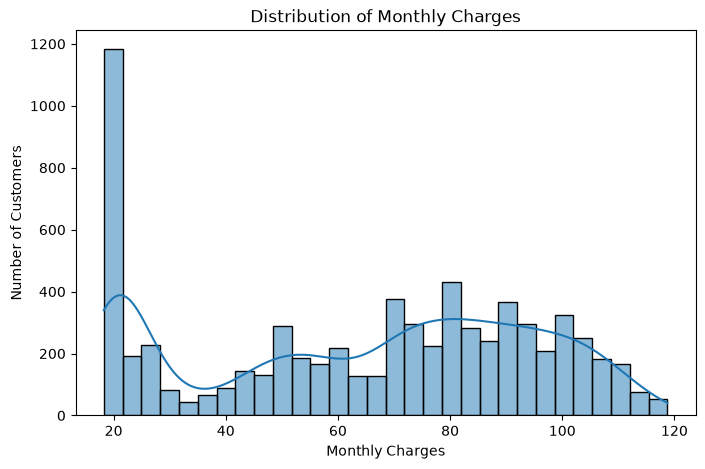

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="monthlycharges", bins=30, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

In [22]:
print(df.columns.tolist())

['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']


### Analysis of Customer Churn

The customer churn chart compares the number of customers who stayed with the company with the number who left. Comparing these groups helps the company understand the extent of customer loss and the importance of customer-retention strategies.


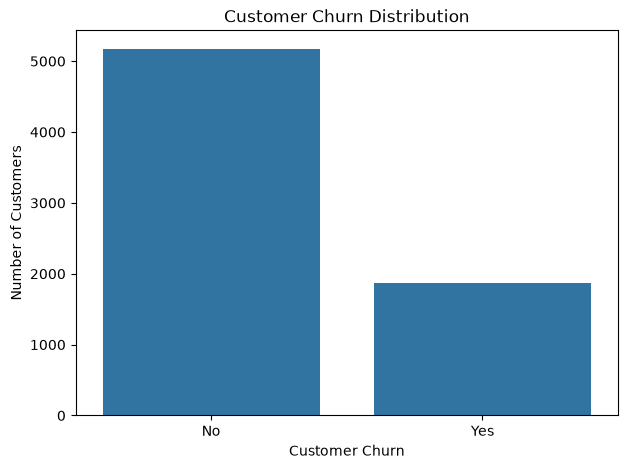

In [23]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()


In [25]:
# Count customers in each churn category
churn_counts = df["churn"].value_counts()

print("Customer Counts:")
print(churn_counts)

# Calculate percentages
churn_percentages = df["churn"].value_counts(normalize=True) * 100

print("\nCustomer Percentages:")
print(churn_percentages.round(2))

Customer Counts:
churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Percentages:
churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


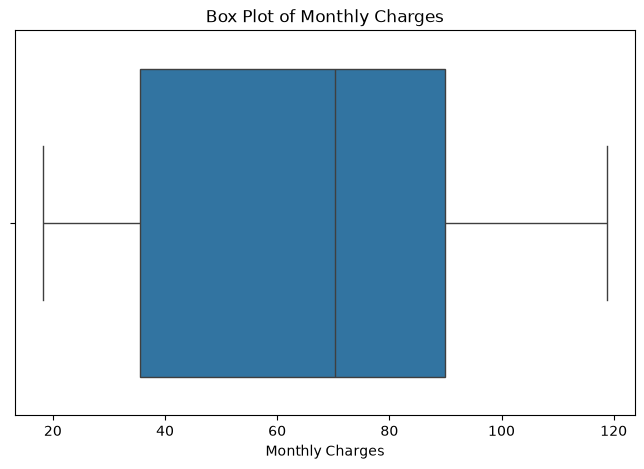

In [26]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="monthlycharges")

plt.title("Box Plot of Monthly Charges")
plt.xlabel("Monthly Charges")

plt.show()


### Analysis of Customer Churn by Gender

This analysis compares customer churn between male and female customers. The churn percentages help identify whether the two groups have different customer-retention patterns. The results can help the company understand its customer base and investigate possible reasons for differences in churn.


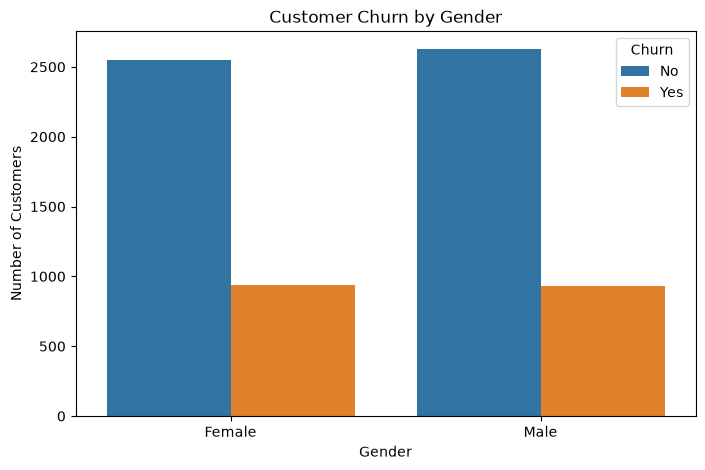

In [27]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="gender", hue="churn")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.show()


### Analysis of Customer Churn by Contract Type

This analysis compares churn across different contract types. By examining the percentage of customers who leave within each contract group, the company can identify which groups have higher churn rates. These findings can support the development of customer-retention strategies.


Customer Churn by Contract Type:
churn             No   Yes
contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


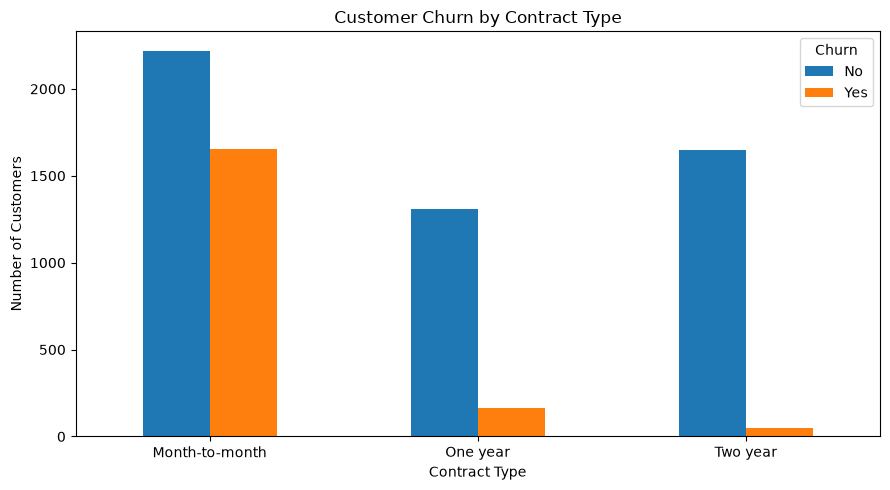

In [28]:

# Calculate churn counts by contract type
contract_churn = pd.crosstab(
    df["contract"],
    df["churn"]
)

print("Customer Churn by Contract Type:")
print(contract_churn)

# Visualize the results
contract_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


Churn Percentage by Contract Type:
churn              No    Yes
contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


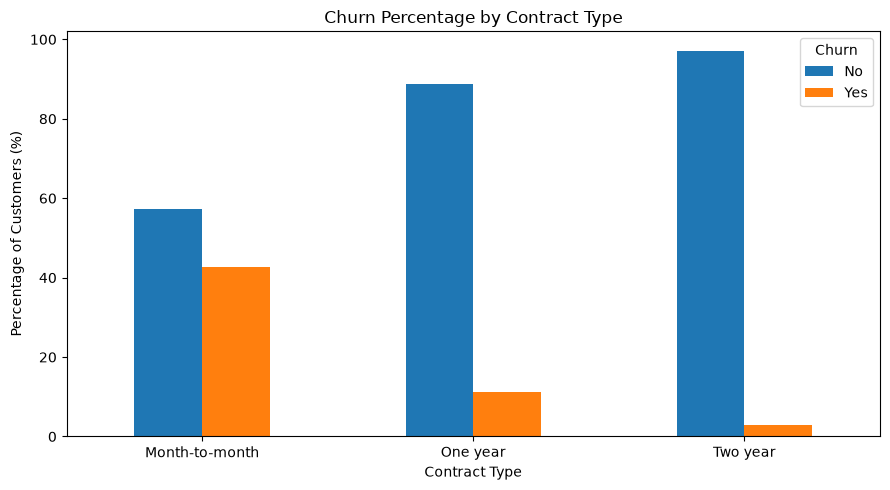

In [29]:

# Calculate the percentage of customers who churned
contract_churn_rate = pd.crosstab(
    df["contract"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Contract Type:")
print(contract_churn_rate.round(2))

# Visualize churn percentages
contract_churn_rate.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


In [30]:

# Group customers according to tenure
def categorize_tenure(months):
    if months <= 12:
        return "0-12 months"
    elif months <= 36:
        return "13-36 months"
    else:
        return "37+ months"

df["tenure_group"] = df["tenure"].apply(categorize_tenure)

# Count customers in each group
tenure_counts = df["tenure_group"].value_counts()

print("Customer Segmentation by Tenure:")
print(tenure_counts)



Customer Segmentation by Tenure:
tenure_group
37+ months      3001
0-12 months     2186
13-36 months    1856
Name: count, dtype: int64


### Customer Segmentation by Tenure

Customers were divided into three groups based on how long they had stayed with the company: 0–12 months, 13–36 months, and 37 months or more. The pie chart shows the proportion of customers in each group. This segmentation helps the company understand its customer lifecycle and identify groups that may need different retention strategies.


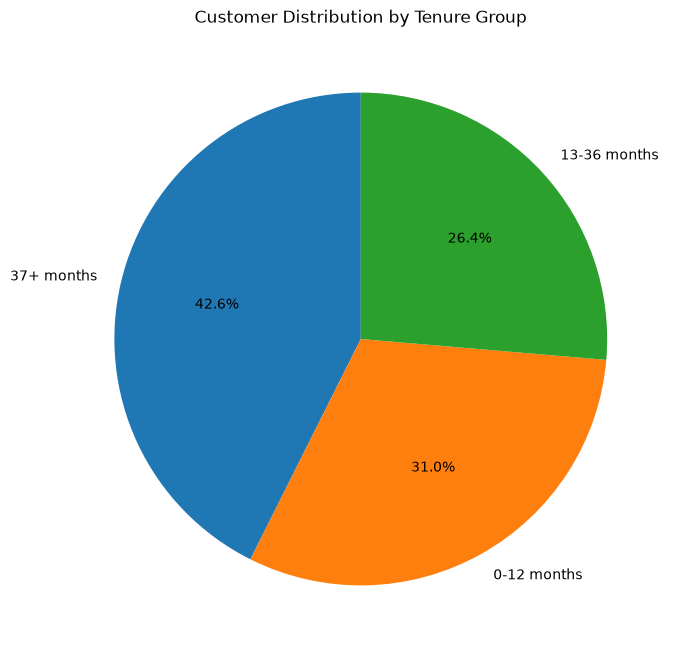

In [31]:

plt.figure(figsize=(8, 8))

plt.pie(
    tenure_counts,
    labels=tenure_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by Tenure Group")
plt.show()


In [32]:

# Calculate average monthly charges for each tenure group
average_charges = df.groupby("tenure_group")["monthlycharges"].mean()

print("Average Monthly Charges by Tenure Group:")
print(average_charges.round(2))


Average Monthly Charges by Tenure Group:
tenure_group
0-12 months     56.10
13-36 months    63.25
37+ months      72.01
Name: monthlycharges, dtype: float64


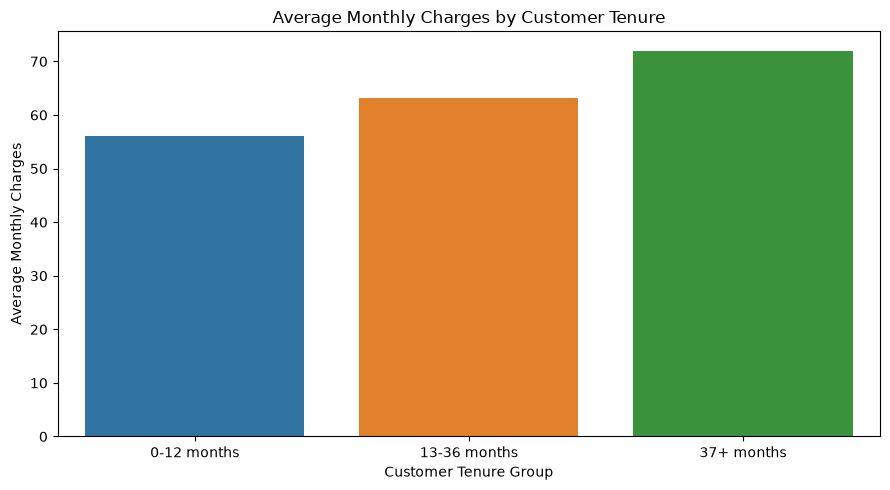

In [33]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="tenure_group",
    y="monthlycharges",
    hue="tenure_group",
    order=["0-12 months", "13-36 months", "37+ months"],
    errorbar=None,
    legend=False
)

plt.title("Average Monthly Charges by Customer Tenure")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Average Monthly Charges")
plt.tight_layout()
plt.show()


In [35]:

# Calculate churn percentage within each tenure group
tenure_churn = pd.crosstab(
    df["tenure_group"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Rate by Tenure Group (%):")
print(tenure_churn.round(2))



Churn Rate by Tenure Group (%):
churn            No    Yes
tenure_group              
0-12 months   52.56  47.44
13-36 months  74.46  25.54
37+ months    88.07  11.93


### Analysis of Customer Churn by Tenure

Customers were grouped according to their tenure: 0–12 months, 13–36 months, and 37 months or more. The churn rates for these groups help identify when customers may be more likely to leave. This information can help the company consider appropriate retention strategies at different stages of the customer lifecycle.


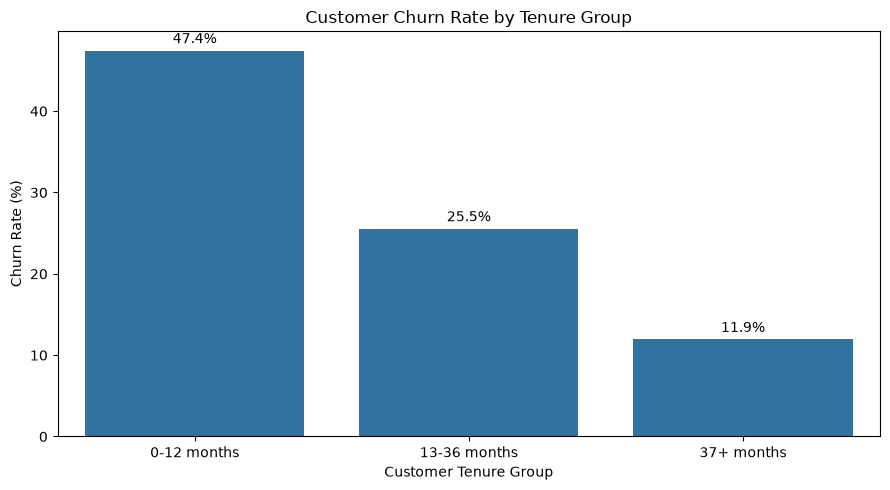

In [37]:

# Select the percentage of customers who churned
churn_by_tenure = tenure_churn["Yes"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Churn Rate (%)")

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



In [38]:

# Calculate churn percentages for each payment method
payment_churn = pd.crosstab(
    df["paymentmethod"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Payment Method:")
print(payment_churn.round(2))


Churn Percentage by Payment Method:
churn                         No    Yes
paymentmethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


### Analysis of Customer Churn by Payment Method

This analysis examines the relationship between payment methods and customer churn. Comparing churn percentages across payment methods helps identify differences in customer-retention patterns. The company can use these findings to investigate whether payment-related factors are associated with customer loss.


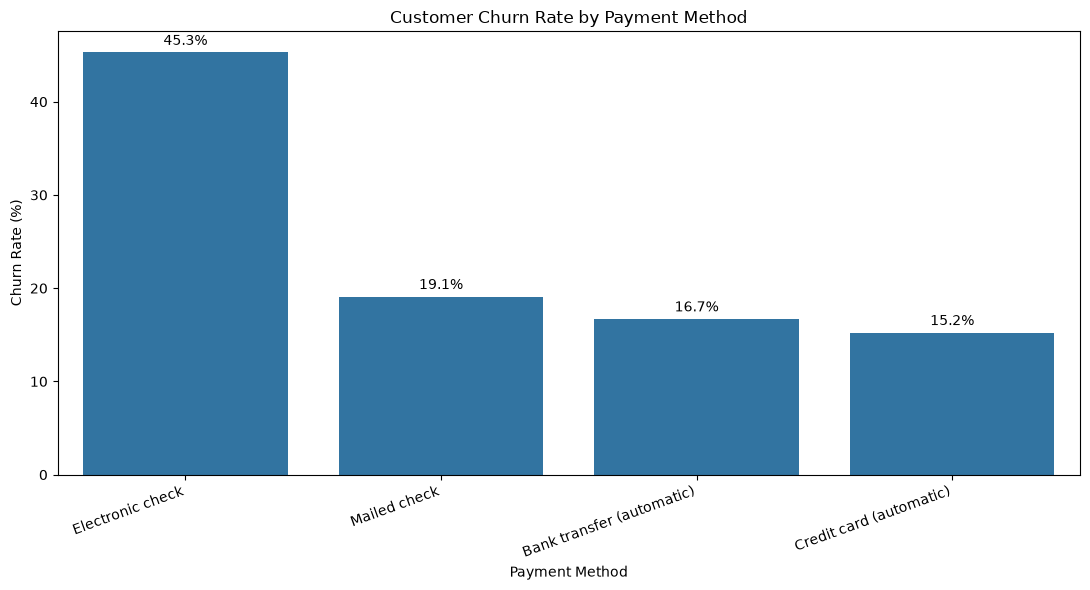

In [39]:

# Select the percentage of customers who churned
payment_churn_rate = payment_churn["Yes"].sort_values(ascending=False)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=payment_churn_rate.index,
    y=payment_churn_rate.values
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



In [40]:

# Calculate churn percentages by senior citizen status
senior_churn = pd.crosstab(
    df["seniorcitizen"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Senior Citizen Status:")
print(senior_churn.round(2))



Churn Percentage by Senior Citizen Status:
churn             No    Yes
seniorcitizen              
0              76.39  23.61
1              58.32  41.68


### Analysis of Customer Churn by Senior Citizen Status

This analysis compares customer churn between senior and non-senior customers. Examining the churn percentages helps determine whether customer-retention patterns differ between these groups. The results describe an association and do not establish that age causes customers to leave.


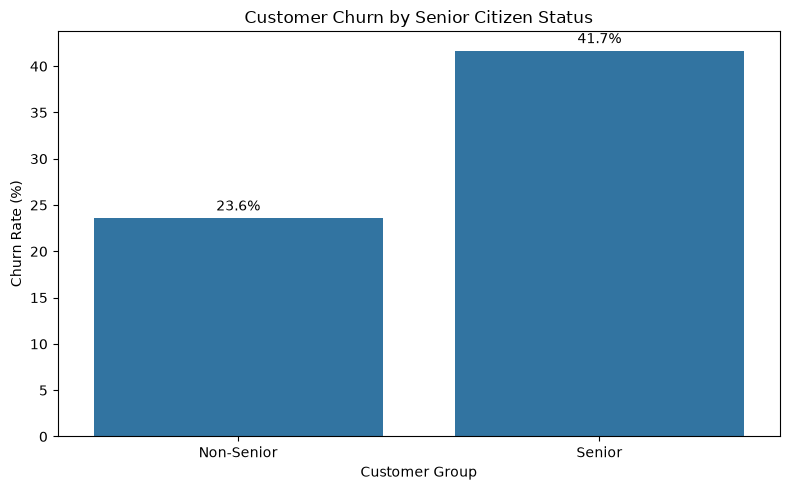

In [41]:

# Select the percentage of customers who churned
senior_churn_rate = senior_churn["Yes"]

# Give the categories readable labels
senior_churn_rate.index = [
    "Non-Senior" if value == 0 else "Senior"
    for value in senior_churn_rate.index
]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=senior_churn_rate.index,
    y=senior_churn_rate.values
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



In [42]:

# Calculate churn percentages by gender
gender_churn = pd.crosstab(
    df["gender"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Gender:")
print(gender_churn.round(2))


Churn Percentage by Gender:
churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


### Customer Behavior Analysis by Churn Status

This analysis compares average tenure, monthly charges, and total charges between customers who stayed and customers who left. Differences in these measures can help the company understand customer behavior and identify characteristics associated with churn. These findings may support further investigation into customer-retention opportunities.


In [43]:

# Compare customer characteristics by churn status
churn_summary = df.groupby("churn").agg(
    average_tenure=("tenure", "mean"),
    average_monthly_charges=("monthlycharges", "mean"),
    average_total_charges=("totalcharges", "mean")
)

print("Customer Summary by Churn Status:")
print(churn_summary.round(2))



Customer Summary by Churn Status:
       average_tenure  average_monthly_charges  average_total_charges
churn                                                                
No              37.57                    61.27                2555.34
Yes             17.98                    74.44                1531.80


## Conclusion

This project analyzed a telecommunications customer churn dataset using Python and data analysis libraries, including Pandas, Matplotlib, and Seaborn. The work involved examining the dataset, cleaning missing and inconsistent values, calculating descriptive statistics, and creating visualizations to explore customer behavior.

Customer segmentation was performed using tenure groups of 0–12 months, 13–36 months, and 37 months or more. Additional analyses examined churn by gender, contract type, payment method, and senior citizen status. Average tenure, monthly charges, and total charges were also compared between customers who stayed and those who left.

The visualizations and statistical summaries provide a foundation for understanding customer-retention patterns. The findings can help the company identify customer groups for further investigation and develop data-informed retention strategies. Specific recommendations should be based on the actual results of the analysis.


In [44]:

# Summarize important customer churn statistics
print("TOTAL CUSTOMERS:", len(df))

print("\nCUSTOMER CHURN COUNTS:")
print(df["churn"].value_counts())

print("\nCUSTOMER CHURN PERCENTAGES:")
print((df["churn"].value_counts(normalize=True) * 100).round(2))

print("\nAVERAGE TENURE BY CHURN STATUS:")
print(df.groupby("churn")["tenure"].mean().round(2))

print("\nAVERAGE MONTHLY CHARGES BY CHURN STATUS:")
print(df.groupby("churn")["monthlycharges"].mean().round(2))


TOTAL CUSTOMERS: 7043

CUSTOMER CHURN COUNTS:
churn
No     5174
Yes    1869
Name: count, dtype: int64

CUSTOMER CHURN PERCENTAGES:
churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

AVERAGE TENURE BY CHURN STATUS:
churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

AVERAGE MONTHLY CHARGES BY CHURN STATUS:
churn
No     61.27
Yes    74.44
Name: monthlycharges, dtype: float64


 Key Findings and Recommendations

 1. Key Findings

The analysis was conducted on a telecommunications customer dataset containing 7,043 customers.

Overall Customer Churn:- The results show that 1,869 customers left the company, representing 26.54% of all customers. The remaining 5,174 customers, or 73.46%, stayed with the company.

Contract Type:- Month-to-month customers had the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts. This suggests that customers with shorter-term contracts may require additional retention attention.

Customer Tenure:- Customers with 0–12 months of tenure had the highest churn rate at 47.44%. The rate decreased to 25.54% for customers with 13–36 months of tenure and 11.93% for customers with 37 months or more. This indicates that early customer retention deserves particular attention.

Payment Method:- Customers using electronic checks had the highest churn rate at 45.29%. Customers using automatic bank transfers had a churn rate of 16.71%, while those using automatic credit card payments had a rate of 15.24%. Mailed-check customers had a churn rate of 19.11%.

Senior Citizen Status:-Senior citizens had a churn rate of 41.68%, compared with 23.61% for non-senior customers. The company could investigate whether service needs, pricing, or other factors contribute to this difference.

Gender:- Female customers had a churn rate of 26.92%, while male customers had a rate of 26.16%. The difference was small, suggesting that gender alone may not be a particularly useful indicator of churn in this dataset.

Monthly Charges and Tenure:- Customers who left had average monthly charges of 74.44 and average tenure of 17.98 months. Customers who stayed had average monthly charges of 61.27 and average tenure of 37.57 months. These differences suggest that higher monthly charges and shorter tenure are associated with customer churn.

2. Recommendations

1. **Improve early customer retention:** Introduce onboarding support and follow-up communication during the first 12 months of service.
2. **Review month-to-month contracts:** Investigate why these customers leave more frequently and consider offering suitable longer-term plans.
3. **Investigate electronic-check churn:** Examine whether payment-related difficulties, billing experiences, or other factors are associated with the high churn rate among electronic-check users.
4. **Review pricing and service value:** Investigate whether customers with higher monthly charges receive sufficient value for the price they pay.
5. **Understand senior customer needs:** Explore service accessibility, customer support, and satisfaction among senior customers.
6. **Monitor churn regularly:** Track churn rates by tenure, contract type, and payment method to evaluate whether retention initiatives are effective.

 3. Conclusion

This project used Python, Pandas, Matplotlib, and Seaborn to explore customer data, clean the dataset, perform exploratory data analysis, and visualize customer segmentation and churn patterns.

The analysis identified higher churn rates among customers with shorter tenure, month-to-month contracts, electronic-check payments, and senior citizen status. Customers who left also had higher average monthly charges and shorter average tenure than customers who stayed.

These findings provide a basis for further investigation and targeted customer-retention strategies. However, the observed relationships do not establish causation. The company should investigate the underlying reasons for these patterns before implementing major changes.
